# CP1 - Data Science and Analytics
### Integrantes do grupo
Felipe Souza Carvalho - 564779  
Gustavo Hackime Costa - 563751  
Luiz Henrique Macedo Graça - 564704  
Riquelme Santos da Mata - 565053

### Dataset: Ocorrências Policiais registradas por ano e mês
Link: https://www.ssp.sp.gov.br/estatistica/dados-mensais

# Descrição do projeto
Esse projeto irá trabalhar com o dataset oficial de estatísticas criminais mensais da Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP). O dataset disponibiliza o número de casos criminais que aconteceram em determinadas cidades de São Paulo de 2022 até 2025. O dataset foi acessado no dia 23/08/2026 e as cidades que serão utilizadas nas análises são: Arujá, Barueri, Caieiras, Guararema, Guarulhos, Itaquacetuba, São Bernado Do Campo e Suzano.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
pasta = Path("datasets")
arquivos = list(pasta.glob("*.xls*"))

## Limpando o Dataset

Leremos cada arquivo (cidade) e cada aba aberto dentro do arquivo (ano)

In [3]:
colunas_mes = ["Janeiro", "Fevereiro", "Marco", "Abril", "Maio", "Junho",
               "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"]

lista_dfs = []
for arquivo in arquivos:
    nome_cidade = arquivo.stem
    abas = pd.read_excel(arquivo, sheet_name=None, dtype=str)

    for ano, df in abas.items():
        for col in colunas_mes + ["Total"]:
            df[col] = df[col].str.replace(".", "", regex=False)  # tira ponto de milhar
            df[col] = df[col].replace("", "0")                    # célula vazia vira "0"
            df[col] = df[col].astype(float)                       # converte pra número
        df["ano"] = ano
        df["cidade"] = nome_cidade
        lista_dfs.append(df)

dados_completos = pd.concat(lista_dfs, ignore_index=True)

c:\Users\Riquelme\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
c:\Users\Riquelme\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
c:\Users\Riquelme\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
c:\Users\Riquelme\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, app

Aqui, iremos criar uma coluna mes para aguardar cada um dos meses, ao invés de ter uma coluna pra cada um dos meses, pois isso dificultaria análises futuras.

In [4]:
dados_longo = dados_completos.melt(
    id_vars=["Natureza", "cidade", "ano"],
    value_vars=colunas_mes,
    var_name="mes",
    value_name="ocorrencias"
)

display(dados_longo.shape)
print(dados_longo.head(3))

(8832, 5)

                                    Natureza cidade   ano      mes  \
0                       HOMICÍDIO DOLOSO (2)  Aruja  2026  Janeiro   
1      Nº DE VÍTIMAS EM HOMICÍDIO DOLOSO (3)  Aruja  2026  Janeiro   
2  HOMICÍDIO DOLOSO POR ACIDENTE DE TRÂNSITO  Aruja  2026  Janeiro   

   ocorrencias  
0          0.0  
1          0.0  
2          0.0  


Tirando 2026

In [5]:
# Removendo 2026
dados_longo = dados_longo[dados_longo["ano"] != "2026"]
print(dados_longo["ano"].unique())
display(dados_longo.head(5))
display(dados_longo.shape)

<StringArray>
['2025', '2024', '2023']
Length: 3, dtype: str


,Natureza,cidade,ano,mes,ocorrencias
23,HOMICÍDIO DOLOSO (2),Aruja,2025,Janeiro,0.0
24,Nº DE VÍTIMAS EM HOMICÍDIO DOLOSO (3),Aruja,2025,Janeiro,0.0
25,HOMICÍDIO DOLOSO POR ACIDENTE DE TRÂNSITO,Aruja,2025,Janeiro,0.0
26,Nº DE VÍTIMAS EM HOMICÍDIO DOLOSO POR ACIDENTE...,Aruja,2025,Janeiro,0.0
27,HOMICÍDIO CULPOSO POR ACIDENTE DE TRÂNSITO,Aruja,2025,Janeiro,0.0


(6624, 5)

### Criando categorias
Aqui criaremos um novo dataframe para separar algumas naturezas que não serão usadas. Por exemplo: o N° de vítimas apresenta um dado sobre as vítimas, mas homícidio doloso mostra um valor atribuído à quantidade de casos. Não faz sentido deixar as duas na mesma tabela, caso contrário trataríamos as duas coisas como um dado só. Com isso também criaremos quatro categorias para facilitar a análise posteriormente, agrupando os crimes.  

Os quatro grupos serão: Crimes contra a vida, Lesões corporais, Crimes sexuais e Crimes patrimoniais.

In [6]:
excluir_da_soma = [
    "Nº DE VÍTIMAS EM HOMICÍDIO DOLOSO (3)",
    "HOMICÍDIO DOLOSO POR ACIDENTE DE TRÂNSITO",
    "TOTAL DE ESTUPRO (4)",
    "ROUBO - OUTROS",
    "Nº DE VÍTIMAS EM HOMICÍDIO DOLOSO POR ACIDENTE DE TRÂNSITO",
    "Nº DE VÍTIMAS EM LATROCÍNIO"

]

dados_ocorrencias = dados_longo[~dados_longo["Natureza"].isin(excluir_da_soma)].copy()
display(dados_ocorrencias.head(5))
display(dados_ocorrencias.shape)
print(f"Existem {dados_ocorrencias["Natureza"].nunique()} categorias")

,Natureza,cidade,ano,mes,ocorrencias
23,HOMICÍDIO DOLOSO (2),Aruja,2025,Janeiro,0.0
27,HOMICÍDIO CULPOSO POR ACIDENTE DE TRÂNSITO,Aruja,2025,Janeiro,0.0
28,HOMICÍDIO CULPOSO OUTROS,Aruja,2025,Janeiro,0.0
29,TENTATIVA DE HOMICÍDIO,Aruja,2025,Janeiro,1.0
30,LESÃO CORPORAL SEGUIDA DE MORTE,Aruja,2025,Janeiro,0.0


(4896, 5)

Existem 17 categorias


In [7]:
mapa_categorias = {
    "HOMICÍDIO DOLOSO (2)": "Crimes contra a vida",
    "HOMICÍDIO CULPOSO POR ACIDENTE DE TRÂNSITO": "Crimes contra a vida",
    "HOMICÍDIO CULPOSO OUTROS": "Crimes contra a vida",
    "TENTATIVA DE HOMICÍDIO": "Crimes contra a vida",
    "LESÃO CORPORAL SEGUIDA DE MORTE": "Crimes contra a vida",
    "LATROCÍNIO": "Crimes contra a vida",

    "LESÃO CORPORAL DOLOSA": "Lesões corporais",
    "LESÃO CORPORAL CULPOSA POR ACIDENTE DE TRÂNSITO": "Lesões corporais",
    "LESÃO CORPORAL CULPOSA - OUTRAS": "Lesões corporais",

    "ESTUPRO": "Crimes Sexuais",
    "ESTUPRO DE VULNERÁVEL": "Crimes Sexuais",

    "TOTAL DE ROUBO - OUTROS (1)": "Crimes patrimoniais",
    "ROUBO DE VEÍCULO": "Crimes patrimoniais",
    "ROUBO A BANCO": "Crimes patrimoniais",
    "ROUBO DE CARGA": "Crimes patrimoniais",
    "FURTO - OUTROS": "Crimes patrimoniais",
    "FURTO DE VEÍCULO": "Crimes patrimoniais",
}

dados_ocorrencias["categoria"] = dados_ocorrencias["Natureza"].map(mapa_categorias)
display(dados_ocorrencias.head(5))
display(dados_ocorrencias.shape)
#Verificando se existe algum dado com NaN
dados_ocorrencias[dados_ocorrencias.isna().any(axis=1)]

,Natureza,cidade,ano,mes,ocorrencias,categoria
23,HOMICÍDIO DOLOSO (2),Aruja,2025,Janeiro,0.0,Crimes contra a vida
27,HOMICÍDIO CULPOSO POR ACIDENTE DE TRÂNSITO,Aruja,2025,Janeiro,0.0,Crimes contra a vida
28,HOMICÍDIO CULPOSO OUTROS,Aruja,2025,Janeiro,0.0,Crimes contra a vida
29,TENTATIVA DE HOMICÍDIO,Aruja,2025,Janeiro,1.0,Crimes contra a vida
30,LESÃO CORPORAL SEGUIDA DE MORTE,Aruja,2025,Janeiro,0.0,Crimes contra a vida


(4896, 6)

,Natureza,cidade,ano,mes,ocorrencias,categoria


## Criando os gráficos
### 1) Volume de ocorrências por ano


    ano  ocorrencias
0  2023      76014.0
1  2024      76187.0
2  2025      73315.0


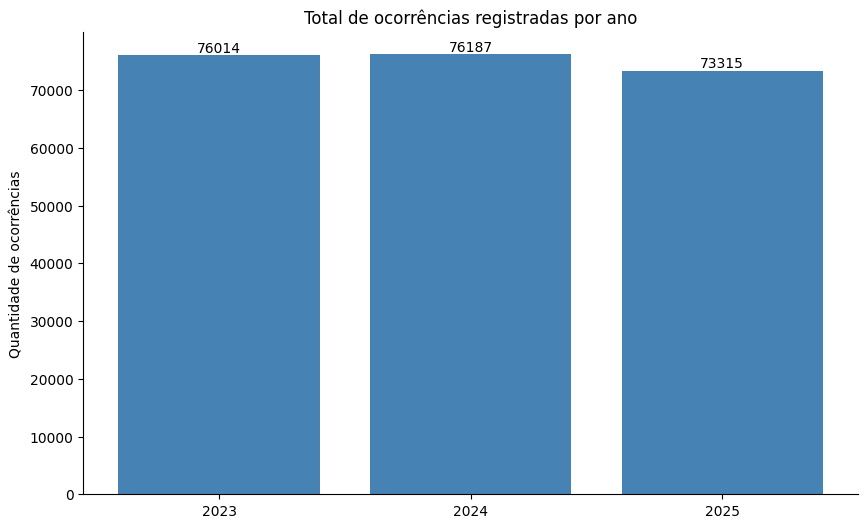

In [8]:
totais_ano = dados_ocorrencias.groupby("ano")["ocorrencias"].sum().reset_index()
print(totais_ano)

fig, ax = plt.subplots(figsize=(10, 6))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

barras = ax.bar(totais_ano["ano"].astype(str), totais_ano["ocorrencias"], color='steelblue')
ax.bar_label(barras, fmt='%.0f')

ax.set_ylabel('Quantidade de ocorrências')
ax.set_title('Total de ocorrências registradas por ano')

plt.show()

O volume total ficou estável entre 2023 e 2024, uma variação de menos de 0,3%. Já entre 2024 e 2025 houve uma queda mais perceptível, de cerca de 3,8%. Em todo o período, a redução foi de aproximadamente 3,6%, sugerindo uma leve tendência de queda concentrada no último ano analisado, não um declínio constante ao longo dos três anos.

### 2) Principais naturezas criminais

In [9]:
categorias = dados_ocorrencias["categoria"].unique()
df_categorias = []
for categoria in categorias:
    df_categorias.append(categoria)

print(df_categorias)


['Crimes contra a vida', 'Lesões corporais', 'Crimes Sexuais', 'Crimes patrimoniais']


              categoria  ocorrencias
0        Crimes Sexuais       2954.0
1  Crimes contra a vida       1882.0
2   Crimes patrimoniais     176480.0
3      Lesões corporais      44200.0


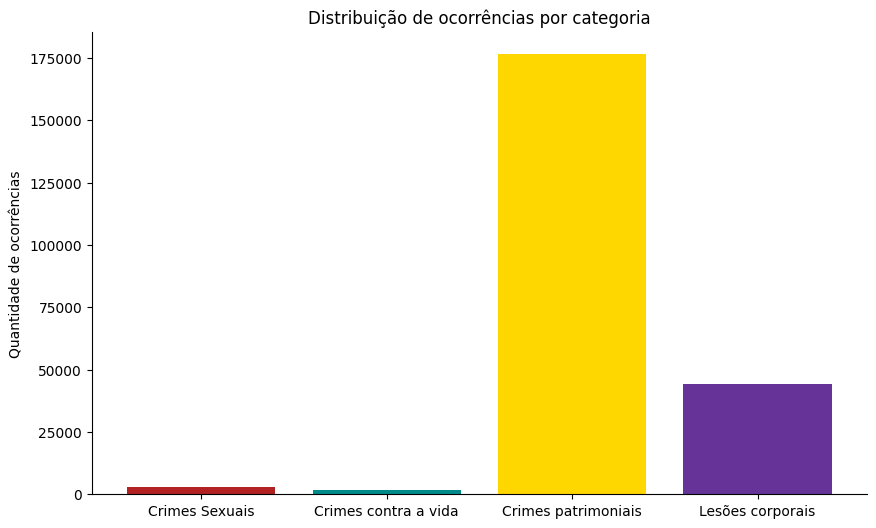

In [10]:
totais_categoria = dados_ocorrencias.groupby("categoria")["ocorrencias"].sum().reset_index()
print(totais_categoria)  # confere os nomes e valores antes de plotar

fig, ax = plt.subplots(figsize=(10, 6))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cores = ['firebrick', 'darkcyan', 'gold', 'rebeccapurple']
ax.bar(totais_categoria["categoria"], totais_categoria["ocorrencias"], color=cores)

ax.set_ylabel('Quantidade de ocorrências')
ax.set_title('Distribuição de ocorrências por categoria')

plt.show()

Crimes patrimoniais dominam disparadamente o total (176.480 ocorrências), respondendo por mais da metade de tudo que foi registrado, bem à frente de Lesões corporais (44.200). Crimes sexuais (2.954) e Crimes contra a vida (1.882) aparecem com volumes muito menores, o que é esperado dado que homicídio e crimes sexuais tendem a ser numericamente mais raros que roubo/furto, mesmo sendo mais graves.

Isso sugere que, ao interpretar o indicador geral de criminalidade, vale sempre separar por categoria, pois um KPI agregado tende a ser dominado pelo comportamento de Crimes patrimoniais, escondendo tendências das outras categorias.


### 3) Distribuição de ocorrências nos meses

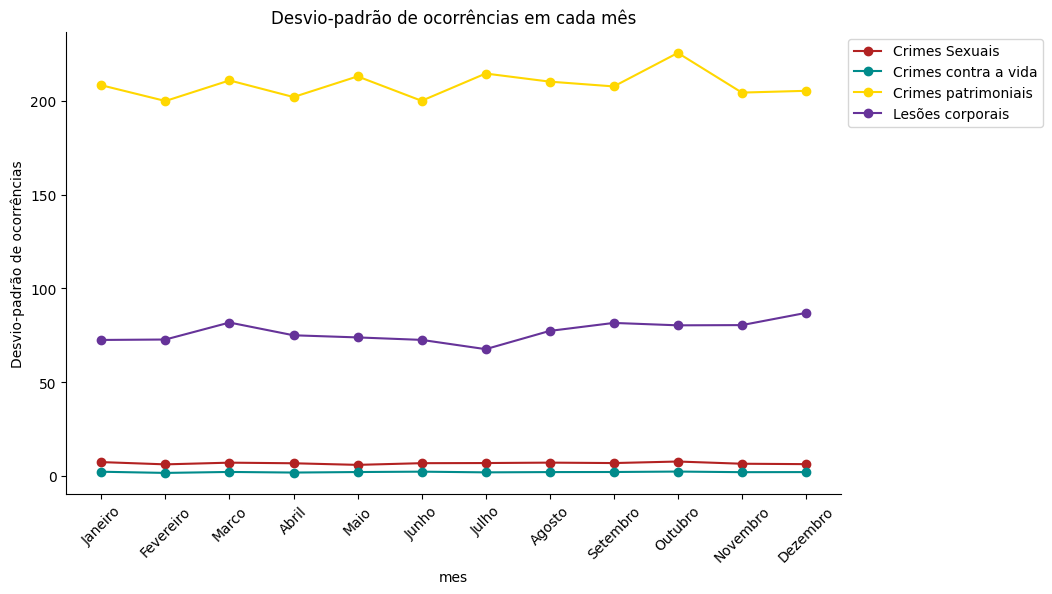

In [11]:
ordem_meses = ["Janeiro", "Fevereiro", "Marco", "Abril", "Maio", "Junho",
               "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"]

dados_ocorrencias["mes"] = pd.Categorical(
    dados_ocorrencias["mes"], categories=ordem_meses, ordered=True
)

desvio_por_mes_categoria = dados_ocorrencias.groupby(
    ["mes", "categoria"], observed=True
)["ocorrencias"].std().reset_index()

tabela_desvio = desvio_por_mes_categoria.pivot(index="mes", columns="categoria", values="ocorrencias")

fig, ax = plt.subplots(figsize=(10, 6))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cores = ['firebrick', 'darkcyan', 'gold', 'rebeccapurple']
tabela_desvio.plot(kind="line", ax=ax, marker='o', color=cores)

ax.set_ylabel('Desvio-padrão de ocorrências')
ax.set_title('Desvio-padrão de ocorrências em cada mês')
plt.xticks(rotation=45)
plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_xticks(range(len(tabela_desvio.index)))
ax.set_xticklabels(tabela_desvio.index, rotation=45)
plt.show()

Os valores de desvio-padrão ficam bastante próximos entre si ao longo dos 12 meses, variando num intervalo estreito de aproximadamente 129,7 (Junho) a 145,9 (Outubro), uma diferença de cerca de 12%. Isso indica que não há um padrão sazonal forte de dispersão: a variabilidade entre naturezas/cidades não muda muito dependendo da época do ano.

Outubro se destaca como o mês de maior dispersão (145,9), enquanto Junho e Fevereiro têm os valores mais baixos (por volta de 129–130), mas, dado o quão próximos todos os valores estão, essa diferença provavelmente reflete mais ruído normal do que um evento sazonal identificável.

### 4) Evolução dos principais indicadores

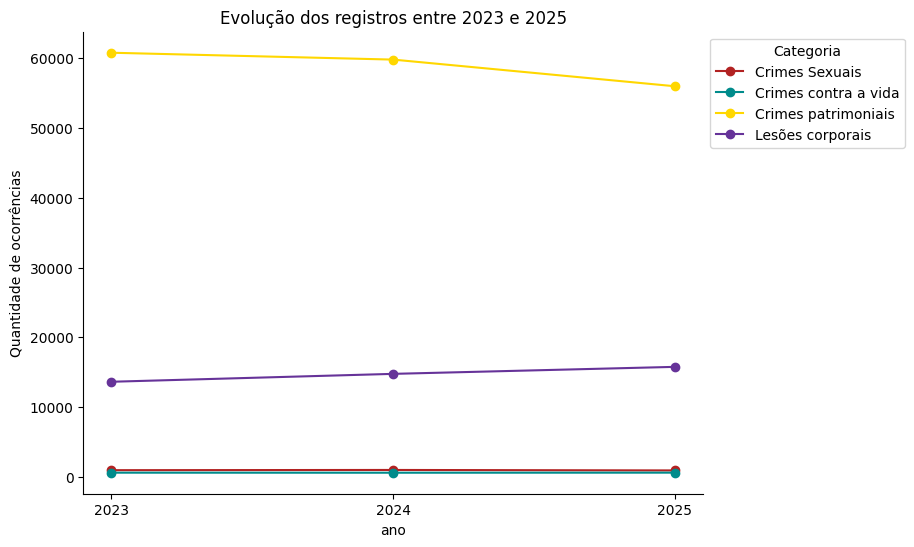

In [12]:
evolucao_categoria = dados_ocorrencias.groupby(["ano", "categoria"])["ocorrencias"].sum().reset_index()
tabela_pivot = evolucao_categoria.pivot(index="ano", columns="categoria", values="ocorrencias")

fig, ax = plt.subplots(figsize=(8, 6))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

tabela_pivot.plot(kind="line", ax=ax, marker='o', color=cores)

ax.set_ylabel('Quantidade de ocorrências')
ax.set_title('Evolução dos registros entre 2023 e 2025')
ax.set_xticks(range(len(tabela_pivot.index)))
ax.legend(title='Categoria', loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

Crimes patrimoniais seguem sendo, disparadamente, a categoria dominante, mas com queda consistente ano a ano: de 60.755 (2023) para 59.771 (2024) e 55.954 (2025), uma redução acumulada de aproximadamente 7,9% no período, concentrada principalmente entre 2024 e 2025 (-6,4%).

Lesões corporais têm trajetória oposta: cresce de forma constante, de 13.645 (2023) para 14.776 (2024) e 15.779 (2025), um aumento acumulado de cerca de 15,6% no período, o crescimento mais consistente entre as quatro categorias.

Crimes sexuais oscila sem tendência clara (986 → 1.018 → 950), enquanto Crimes contra a vida se mantém praticamente estável ao longo dos três anos (628 → 622 → 632), com variações pequenas o suficiente para serem consideradas ruído estatístico em vez de tendência real.


## KPIs

### Variação percentual (total, 2023 → 2025)

In [13]:
import plotly.graph_objects as go

ocorrencias_2023 = totais_ano.loc[totais_ano["ano"] == "2023", "ocorrencias"].values[0]
ocorrencias_2025 = totais_ano.loc[totais_ano["ano"] == "2025", "ocorrencias"].values[0]

fig = go.Figure(go.Indicator(
    mode="number+delta",
    value=ocorrencias_2025,
    delta={"reference": ocorrencias_2023, "relative": True, "valueformat": ".1%", "increasing": {"color": "red"}, "decreasing": {"color": "green"}},
    title={"text": "Ocorrências totais (2025 vs. 2023)"},
))
fig.show()

### Variação por natureza/categoria

Isso gera um indicador por categoria (4 no total), cada um mostrando a variação % daquela categoria entre 2023 e 2025.

In [14]:
for categoria in evolucao_categoria["categoria"].unique():
    valor_2023 = evolucao_categoria.query("ano == '2023' and categoria == @categoria")["ocorrencias"].values[0]
    valor_2025 = evolucao_categoria.query("ano == '2025' and categoria == @categoria")["ocorrencias"].values[0]

    fig = go.Figure(go.Indicator(
        mode="number+delta",
        value=valor_2025,
        delta={"reference": valor_2023, "relative": True, "valueformat": ".1%", "increasing": {"color": "red"}, "decreasing": {"color": "green"}},
        title={"text": categoria}
    ))
    fig.show()

### Média mensal

In [15]:
media_mensal = dados_ocorrencias.groupby("mes", observed=True)["ocorrencias"].sum().mean()
fig = go.Figure(go.Indicator(mode="number", value=media_mensal, title={"text": "Média mensal de ocorrências"}))
fig.show()

### Desvio-padrão mensal

In [16]:
dados_mensais_desvio = dados_ocorrencias.copy()

dados_mensais_desvio["mes"] = pd.Categorical(
    dados_ocorrencias["mes"], categories=ordem_meses, ordered=True
)

desvio_por_mes = dados_mensais_desvio.groupby("mes", observed=True)["ocorrencias"].std().reset_index()

fig = go.Figure(go.Indicator(mode="number", value=desvio_por_mes["ocorrencias"].mean(), title={"text": "Desvio-padrão médio mensal"}))
fig.show()